<a href="https://colab.research.google.com/github/Nismata/Nismata-Sigdel/blob/main/Copy_of_HW_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

#Get sklearn! https://scikit-learn.org/stable/
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance

In [ ]:
df = pd.read_csv('LA_AQS_2023.csv')
df.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [ ]:
# Select ozone.
O3 = df[
    df['Parameter Name'] == 'Ozone'
].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()
O3 = O3.rename(columns={'Arithmetic Mean': 'O3'})
O3['O3'] = O3['O3'] * 1000  # Convert ppm to ppb.

# Select nitrogen dioxide.
NO2 = df[
    df['Parameter Name'] == 'Nitrogen dioxide (NO2)'
].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()
NO2 = NO2.rename(columns={'Arithmetic Mean': 'NO2'})

# Select PM2.5.
PM25 = df[
    df['Parameter Name'] == 'PM2.5 - Local Conditions'
].groupby('Date (Local)')['Arithmetic Mean'].mean().reset_index()
PM25 = PM25.rename(columns={'Arithmetic Mean': 'PM2.5'})

# Match daily measurements.
df = pd.merge(O3, NO2, on='Date (Local)', validate='one_to_one')
df = pd.merge(df, PM25, on='Date (Local)', validate='one_to_one')
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=['O3', 'NO2', 'PM2.5'])

# Season must contain class labels, NOT individual dates.
df['Date (Local)'] = pd.to_datetime(df['Date (Local)'])
df['Season'] = df['Date (Local)'].dt.month.map({
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    6: 'Summer', 7: 'Summer', 8: 'Summer'
})
df = df.dropna(subset=['Season']).copy()

print(df['Season'].value_counts())
df.head()

Season
Summer    92
Winter    59
Name: count, dtype: int64


,Date (Local),O3,NO2,PM2.5,Season
0,2023-01-01,30.0600,4.683333,4.457500,Winter
1,2023-01-10,20.7685,12.737500,5.330833,Winter
2,2023-01-11,12.0880,20.975000,10.850833,Winter
3,2023-01-12,8.7840,24.610417,7.243537,Winter
4,2023-01-13,8.6570,27.406250,9.686667,Winter


In [ ]:
# Create the correct season labels.
df['Date (Local)'] = pd.to_datetime(df['Date (Local)'])

df['Season'] = df['Date (Local)'].dt.month.map({
    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer'
})

# Keep complete summer and winter observations.
df = df.dropna(subset=['O3', 'NO2', 'PM2.5', 'Season']).copy()

print(df['Season'].value_counts())

# Select predictors and target.
X_epa = df[['O3', 'NO2', 'PM2.5']]
y_epa = df['Season']

# Split the data.
X_epa_train, X_epa_test, y_epa_train, y_epa_test = train_test_split(
    X_epa,
    y_epa,
    test_size=0.20,
    random_state=42,
    stratify=y_epa
)

# Scale the predictors.
scaler = StandardScaler()

X_epa_train_scaled = scaler.fit_transform(X_epa_train)
X_epa_test_scaled = scaler.transform(X_epa_test)

Season
Summer    92
Winter    59
Name: count, dtype: int64


In [ ]:
# Fit the ridge model BEFORE calculating permutation importance.
# Reuse the penalty selected in the earlier homework.
ridge_model = RidgeClassifier(alpha=35.5648)
ridge_model.fit(X_epa_train_scaled, y_epa_train)

epa_accuracy = ridge_model.score(X_epa_test_scaled, y_epa_test)
print('EPA test accuracy:', epa_accuracy)
print('EPA test classification error:', 1 - epa_accuracy)

EPA test accuracy: 0.9032258064516129
EPA test classification error: 0.09677419354838712


  Feature  Importance  Standard deviation
1     NO2    0.143011            0.070025
2   PM2.5    0.111828            0.054447
0      O3    0.066667            0.038108


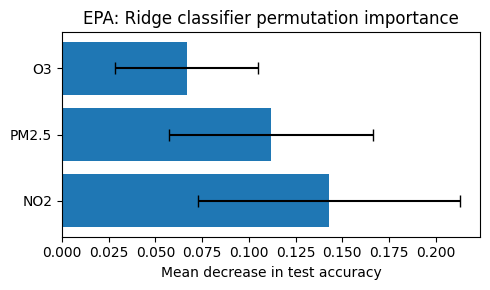

In [ ]:
r_epa = permutation_importance(
    ridge_model,
    X_epa_test_scaled,
    y_epa_test,
    scoring='accuracy',
    n_repeats=30,
    random_state=42
)

epa_importance = pd.DataFrame({
    'Feature': X_epa.columns,
    'Importance': r_epa.importances_mean,
    'Standard deviation': r_epa.importances_std
})

epa_importance = epa_importance.sort_values(
    'Importance',
    ascending=False
)

print(epa_importance)

plt.figure(figsize=(5, 3))

plt.barh(
    epa_importance['Feature'],
    epa_importance['Importance'],
    xerr=epa_importance['Standard deviation'],
    capsize=4
)


plt.axvline(0, color='black', linewidth=0.2)
plt.xlabel('Mean decrease in test accuracy')
plt.title('EPA: Ridge classifier permutation importance')
plt.tight_layout()
plt.show()

In [ ]:
waves = pd.read_csv('Waves_2023.txt', sep=r'\s+')

wavesML = waves[['WVHT', 'DPD', 'APD', 'MWD', 'WTMP']].copy()

wavesML = wavesML[wavesML['WVHT'] < 99]
wavesML = wavesML[wavesML['DPD'] < 99]
wavesML = wavesML[wavesML['APD'] < 99]
wavesML = wavesML[wavesML['MWD'] < 999]
wavesML = wavesML[wavesML['WTMP'] < 99]

wavesML = wavesML.dropna()

wavesML.head()

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5


In [ ]:
X_buoy = wavesML[['DPD', 'APD', 'MWD', 'WTMP']]
y_buoy = wavesML['WVHT']

X_buoy_train, X_buoy_other, y_buoy_train, y_buoy_other = train_test_split(
    X_buoy,
    y_buoy,
    test_size=0.20,
    random_state=42
)

X_buoy_val, X_buoy_test, y_buoy_val, y_buoy_test = train_test_split(
    X_buoy_other,
    y_buoy_other,
    test_size=0.50,
    random_state=42
)

In [ ]:
# XGBoost.
regBoosting = xgb.XGBRegressor(
    n_estimators=42,
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=42
)

regBoosting.fit(X_buoy_train, y_buoy_train)

# Decision tree.
regTree = DecisionTreeRegressor(random_state=42)

regTree.fit(X_buoy_train, y_buoy_train)

# Linear regression.
regLinear = linear_model.LinearRegression()

regLinear.fit(X_buoy_train, y_buoy_train)

LinearRegression()

In [ ]:
r_boosting = permutation_importance(
    regBoosting,
    X_buoy_test,
    y_buoy_test,
    scoring='neg_root_mean_squared_error',
    n_repeats=30,
    random_state=42
)

r_tree = permutation_importance(
    regTree,
    X_buoy_test,
    y_buoy_test,
    scoring='neg_root_mean_squared_error',
    n_repeats=30,
    random_state=42
)

r_linear = permutation_importance(
    regLinear,
    X_buoy_test,
    y_buoy_test,
    scoring='neg_root_mean_squared_error',
    n_repeats=30,
    random_state=42
)

buoy_importance = pd.DataFrame({
    'Feature': X_buoy.columns,
    'XGBoost': r_boosting.importances_mean,
    'Decision tree': r_tree.importances_mean,
    'Linear regression': r_linear.importances_mean
})

buoy_importance

,Feature,XGBoost,Decision tree,Linear regression
0,DPD,0.120950,0.165741,0.016299
1,APD,0.168183,0.233354,0.090178
2,MWD,0.157857,0.186976,0.017360
3,WTMP,0.157495,0.165573,0.020727


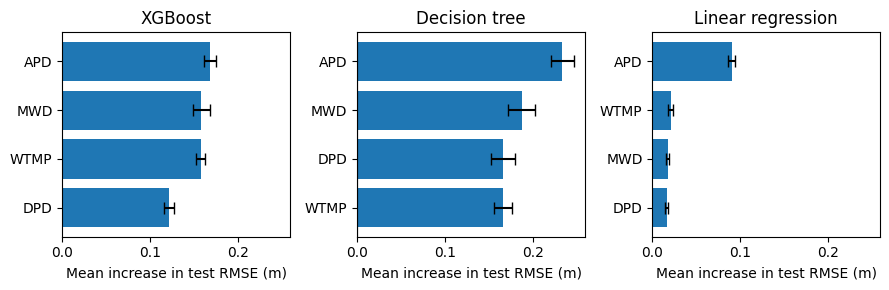

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(9, 3),
    sharex=True
)

# XGBoost.
order = r_boosting.importances_mean.argsort()

axes[0].barh(
    X_buoy.columns[order],
    r_boosting.importances_mean[order],
    xerr=r_boosting.importances_std[order],
    capsize=4
)
axes[0].set_title('XGBoost')
axes[0].set_xlabel('Mean increase in test RMSE (m)')
axes[0].axvline(0, color='black', linewidth=0.2)

# Decision tree.
order = r_tree.importances_mean.argsort()

axes[1].barh(
    X_buoy.columns[order],
    r_tree.importances_mean[order],
    xerr=r_tree.importances_std[order],
    capsize=4
)
axes[1].set_title('Decision tree')
axes[1].set_xlabel('Mean increase in test RMSE (m)')
axes[1].axvline(0, color='black', linewidth=0.8)

# Linear regression.
order = r_linear.importances_mean.argsort()

axes[2].barh(
    X_buoy.columns[order],
    r_linear.importances_mean[order],
    xerr=r_linear.importances_std[order],
    capsize=4
)
axes[2].set_title('Linear regression')
axes[2].set_xlabel('Mean increase in test RMSE (m)')
axes[2].axvline(0, color='black', linewidth=0.2)

plt.tight_layout()
plt.show()

In [ ]:
# EPA ranking.
print('EPA ridge classifier:')
print(
    epa_importance[['Feature', 'Importance']]
    .sort_values('Importance', ascending=False)
    .to_string(index=False)
)

# Use feature names as the NOAA table index.
buoy_scores = buoy_importance.set_index('Feature')

print('\nNOAA XGBoost:')
print(buoy_scores['XGBoost'].sort_values(ascending=False))

print('\nNOAA decision tree:')
print(buoy_scores['Decision tree'].sort_values(ascending=False))

print('\nNOAA linear regression:')
print(buoy_scores['Linear regression'].sort_values(ascending=False))

# Compare model rankings.
buoy_ranks = buoy_scores.rank(
    ascending=False,
    method='min'
)

print('\nNOAA rankings: 1 = most important')
print(buoy_ranks)

same_rankings = (
    buoy_ranks['XGBoost'].equals(buoy_ranks['Decision tree']) and
    buoy_ranks['XGBoost'].equals(buoy_ranks['Linear regression'])
)

print('\nAre all three NOAA rankings identical?', same_rankings)

EPA ridge classifier:
Feature  Importance
    NO2    0.143011
  PM2.5    0.111828
     O3    0.066667

NOAA XGBoost:
Feature
APD     0.168183
MWD     0.157857
WTMP    0.157495
DPD     0.120950
Name: XGBoost, dtype: float64

NOAA decision tree:
Feature
APD     0.233354
MWD     0.186976
DPD     0.165741
WTMP    0.165573
Name: Decision tree, dtype: float64

NOAA linear regression:
Feature
APD     0.090178
WTMP    0.020727
MWD     0.017360
DPD     0.016299
Name: Linear regression, dtype: float64

NOAA rankings: 1 = most important
         XGBoost  Decision tree  Linear regression
Feature                                           
DPD          4.0            3.0                4.0
APD          1.0            1.0                1.0
MWD          2.0            2.0                3.0
WTMP         3.0            4.0                2.0

Are all three NOAA rankings identical? False
